# 4 · Does applause line up with the stock's reaction?

This notebook runs the pre-registered plan in `docs/analysis_plan.md`: the primary
regression of SCAR[0,+1] on the within-company z-score of applause share with company fixed
effects and a wild cluster bootstrap over the nine companies, then the secondary families
(Benjamini–Hochberg corrected), robustness checks, a tercile sort and a placebo test.

In [1]:
%load_ext autoreload
%autoreload 2
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display
from unpacked_applause.config import FIGURES, PROCESSED, TABLES
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [2]:
results = json.loads((TABLES / "results.json").read_text())
pd.Series(results["primary"])

beta           0.0021
se_hc3         0.0763
ci_lo         -0.1475
ci_hi          0.1517
p_hc3          0.9782
t_cr1          0.0248
p_wcb          0.9792
n            250.0000
n_clusters     9.0000
dtype: float64

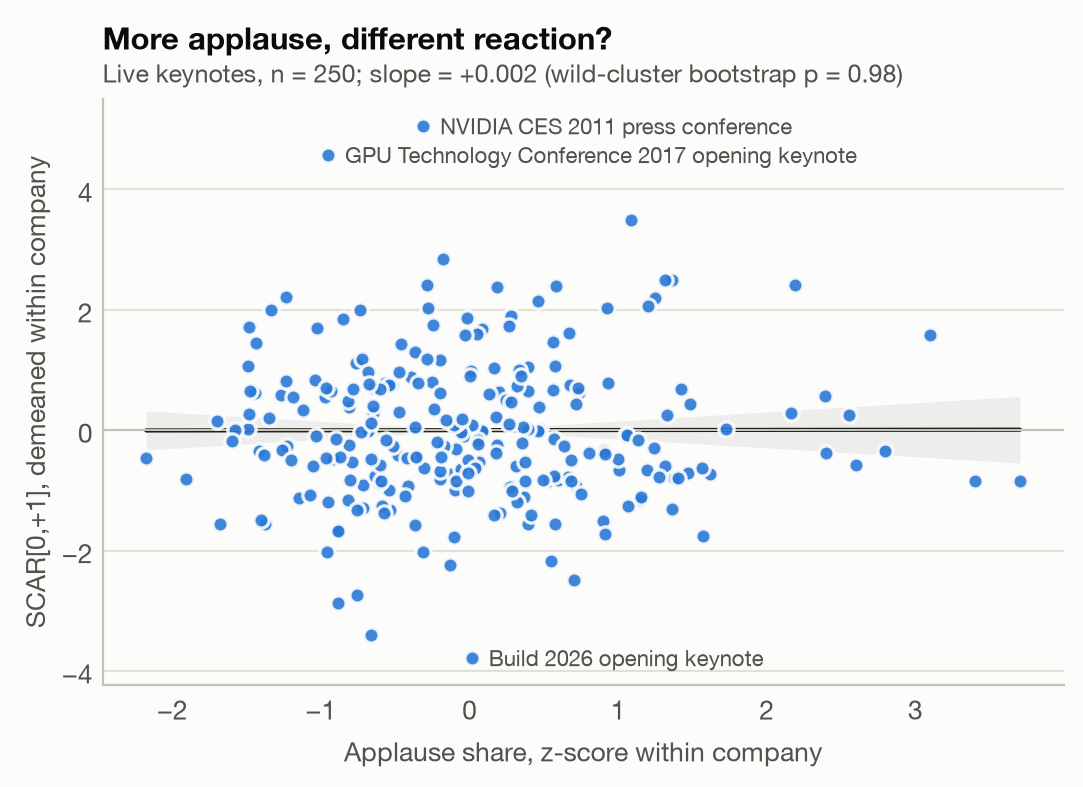

In [3]:
display(Image(filename=str(FIGURES / "primary_scatter.png")))

In [4]:
pd.read_csv(TABLES / "secondary_outcomes.csv")[["outcome", "beta", "ci_lo", "ci_hi", "p_hc3", "p_wcb", "q_bh", "n"]]

,outcome,beta,ci_lo,ci_hi,p_hc3,p_wcb,q_bh,n
0,"SCAR[0,0]",0.0663,-0.0958,0.2284,0.4227,0.5159,0.8431,250
1,"SCAR[-1,+1]",0.0107,-0.1273,0.1487,0.8788,0.9089,0.9089,250
2,"SCAR[0,+5]",0.0502,-0.1163,0.2166,0.5549,0.4507,0.8431,250
3,"SCAR[+2,+20]",0.0177,-0.1358,0.1713,0.8208,0.7026,0.8431,248
4,"|SCAR[0,+1]|",-0.0250,-0.1202,0.0701,0.6059,0.5424,0.8431,250
5,"Abnormal log volume [0,+1] (std.)",0.0496,-0.0823,0.1815,0.4615,0.6058,0.8431,250


In [5]:
pd.read_csv(TABLES / "secondary_measures.csv")[["measure", "beta", "ci_lo", "ci_hi", "p_hc3", "p_wcb", "q_bh", "n"]]

,measure,beta,ci_lo,ci_hi,p_hc3,p_wcb,q_bh,n
0,Ovations per minute,-0.0057,-0.1550,0.1436,0.9404,0.9389,0.9527,250
1,Longest ovation (log seconds),0.0405,-0.1129,0.1939,0.6048,0.7333,0.9527,250
2,Mean clap probability,-0.0060,-0.1588,0.1467,0.9381,0.9527,0.9527,250
3,Cheering share,-0.0758,-0.2123,0.0607,0.2763,0.2556,0.9527,250
4,Hype index (1st principal component),-0.0071,-0.1526,0.1385,0.9243,0.9442,0.9527,250


In [6]:
pd.read_csv(TABLES / "robustness.csv")[["group", "spec", "beta", "ci_lo", "ci_hi", "p_wcb", "n"]]

,group,spec,beta,ci_lo,ci_hi,p_wcb,n
0,Normal-return model,Primary: market model (S&P 500 / KOSPI),0.0021,-0.1475,0.1517,0.9792,250
1,Normal-return model,Market-adjusted (beta = 1),0.0055,-0.1372,0.1483,0.9327,250
2,Normal-return model,Constant mean,-0.0134,-0.1542,0.1275,0.7144,250
3,Normal-return model,Nasdaq-100 as market,0.0373,-0.1191,0.1937,0.7105,250
4,Normal-return model,Fama-French 3-factor (US listings),0.0801,-0.0853,0.2455,0.3760,221
5,Controls,"+ pre-event run-up CAR[-10,-1]",0.0137,-0.1335,0.1609,0.8807,250
6,Controls,+ log VIX on t0-1,-0.0037,-0.1546,0.1473,0.9663,250
7,Controls,+ log keynote length,-0.0008,-0.1503,0.1487,0.9922,250
8,Controls,+ official-channel video,0.0184,-0.1343,0.1712,0.8376,250
9,Controls,+ product-launch dummy,0.0017,-0.1490,0.1523,0.9846,250


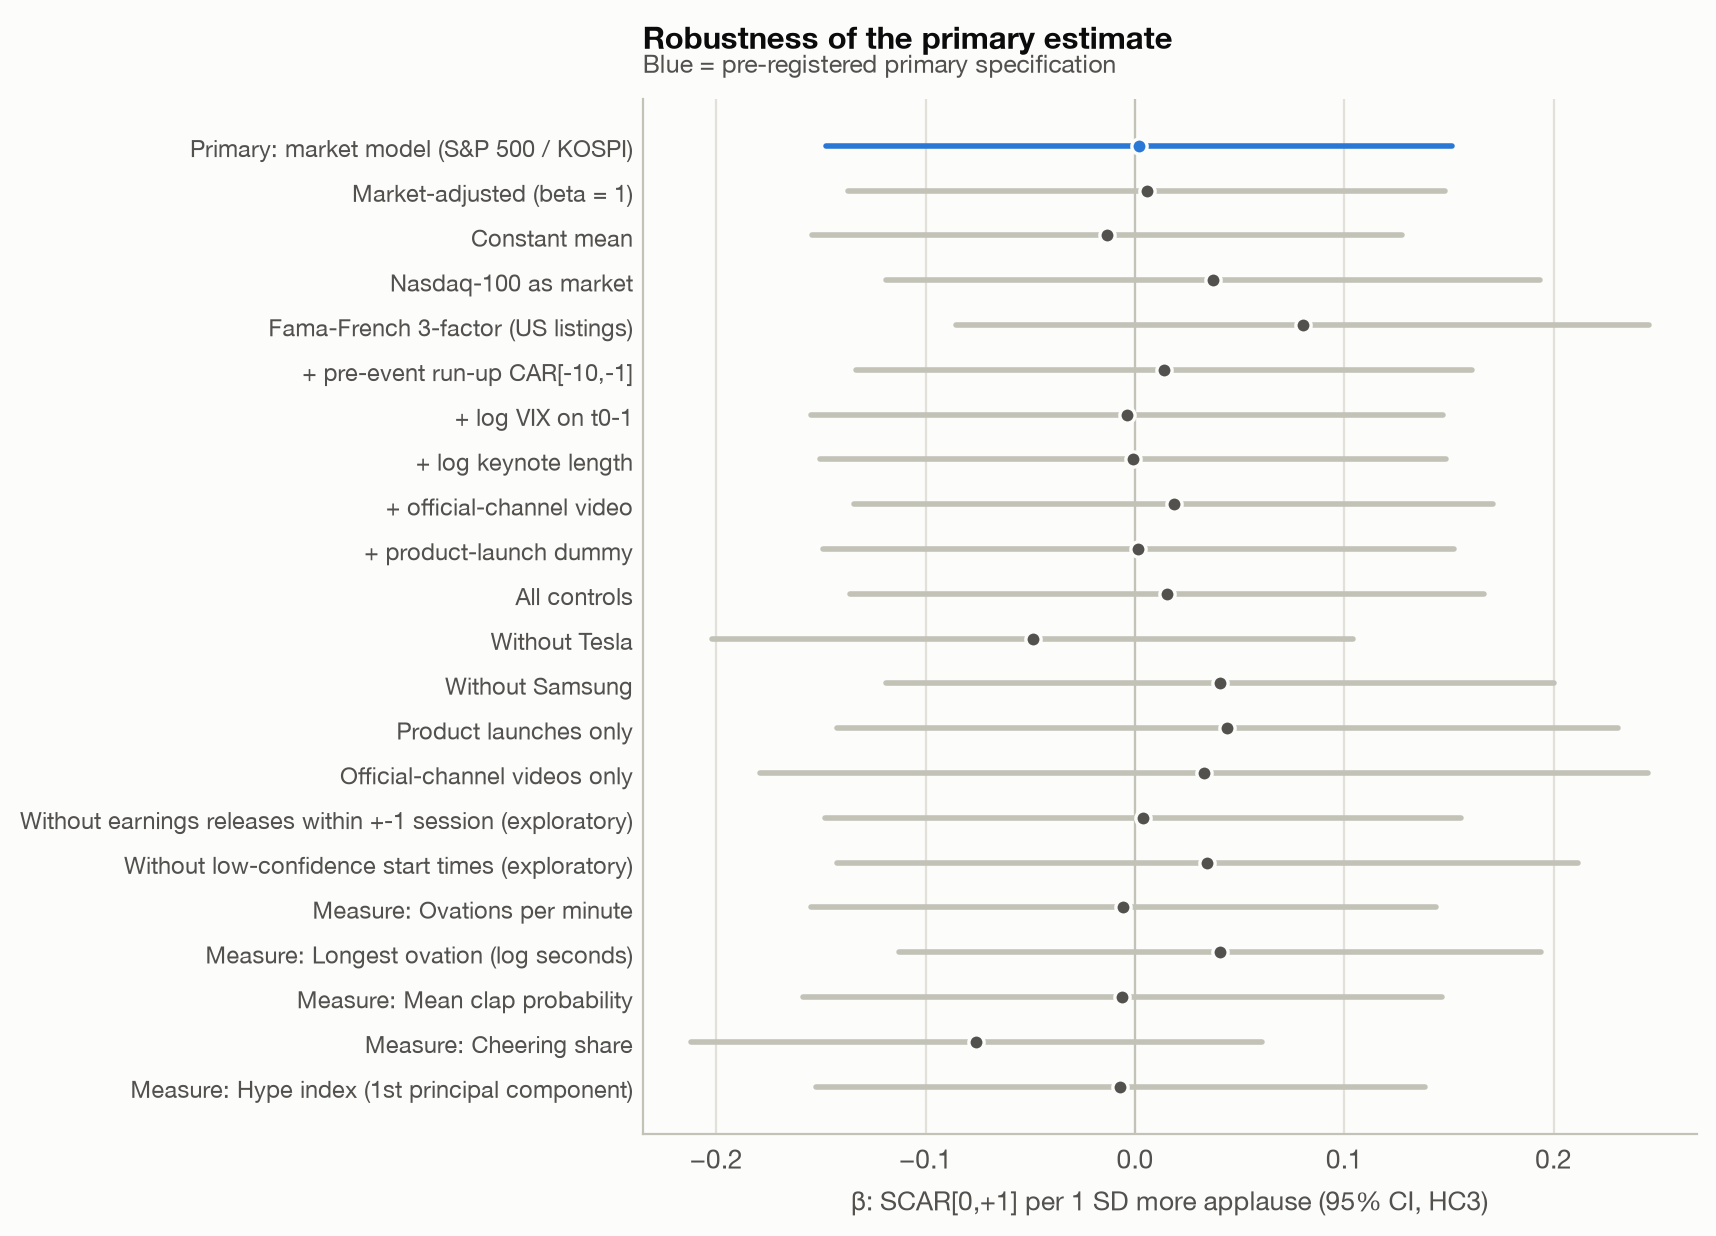

In [7]:
display(Image(filename=str(FIGURES / "robustness.png")))

{'diff': -0.04783257663692843, 'ci_lo': -0.43059129549563074, 'ci_hi': 0.34231209914653815, 'p_welch': 0.8078551379753474}


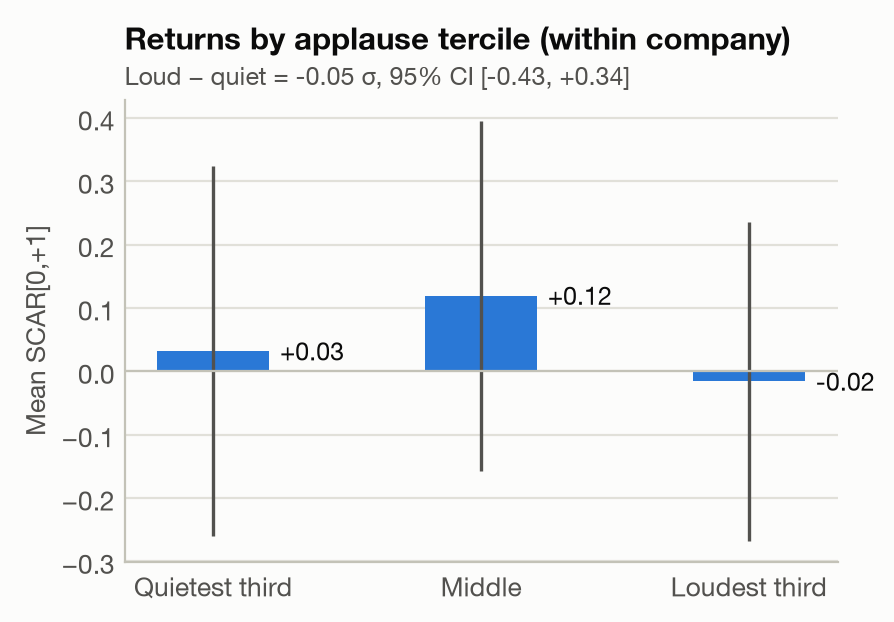

In [8]:
print(results["terciles"])
display(Image(filename=str(FIGURES / "terciles.png")))

{'rho': -0.026695723131570103, 'p_perm': 0.6701, 'n': 250}
{'beta_real': 0.002087451855987115, 'p_placebo': 0.973, 'pool_sizes': {'apple': 3204, 'samsung': 3365, 'google': 3643, 'nvidia': 3488, 'microsoft': 3390, 'tesla': 3019, 'amazon': 3916, 'meta': 2937, 'amd': 3626}}


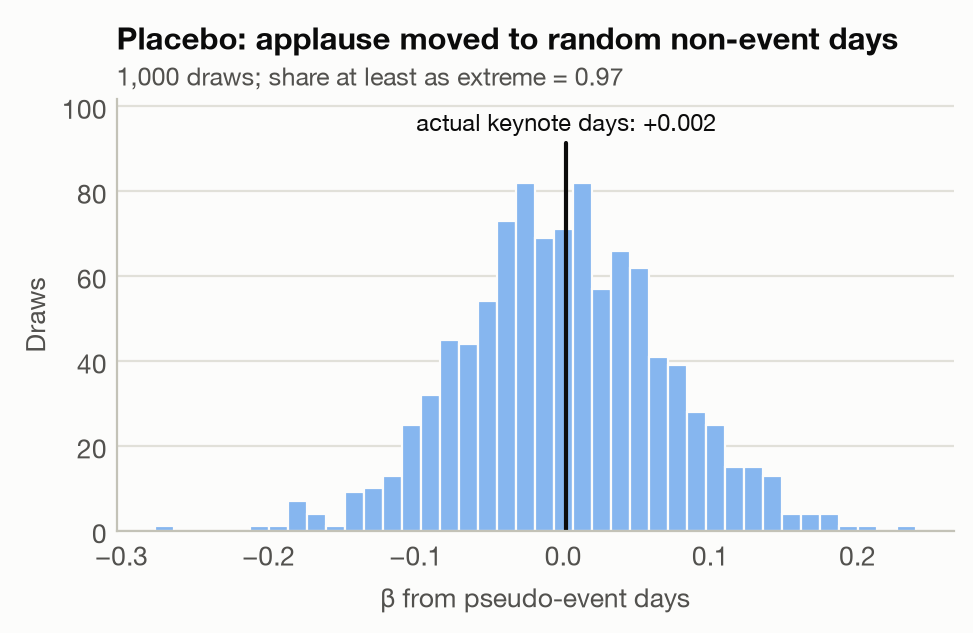

In [9]:
print(results["spearman"])
print(results["placebo"])
display(Image(filename=str(FIGURES / "placebo.png")))

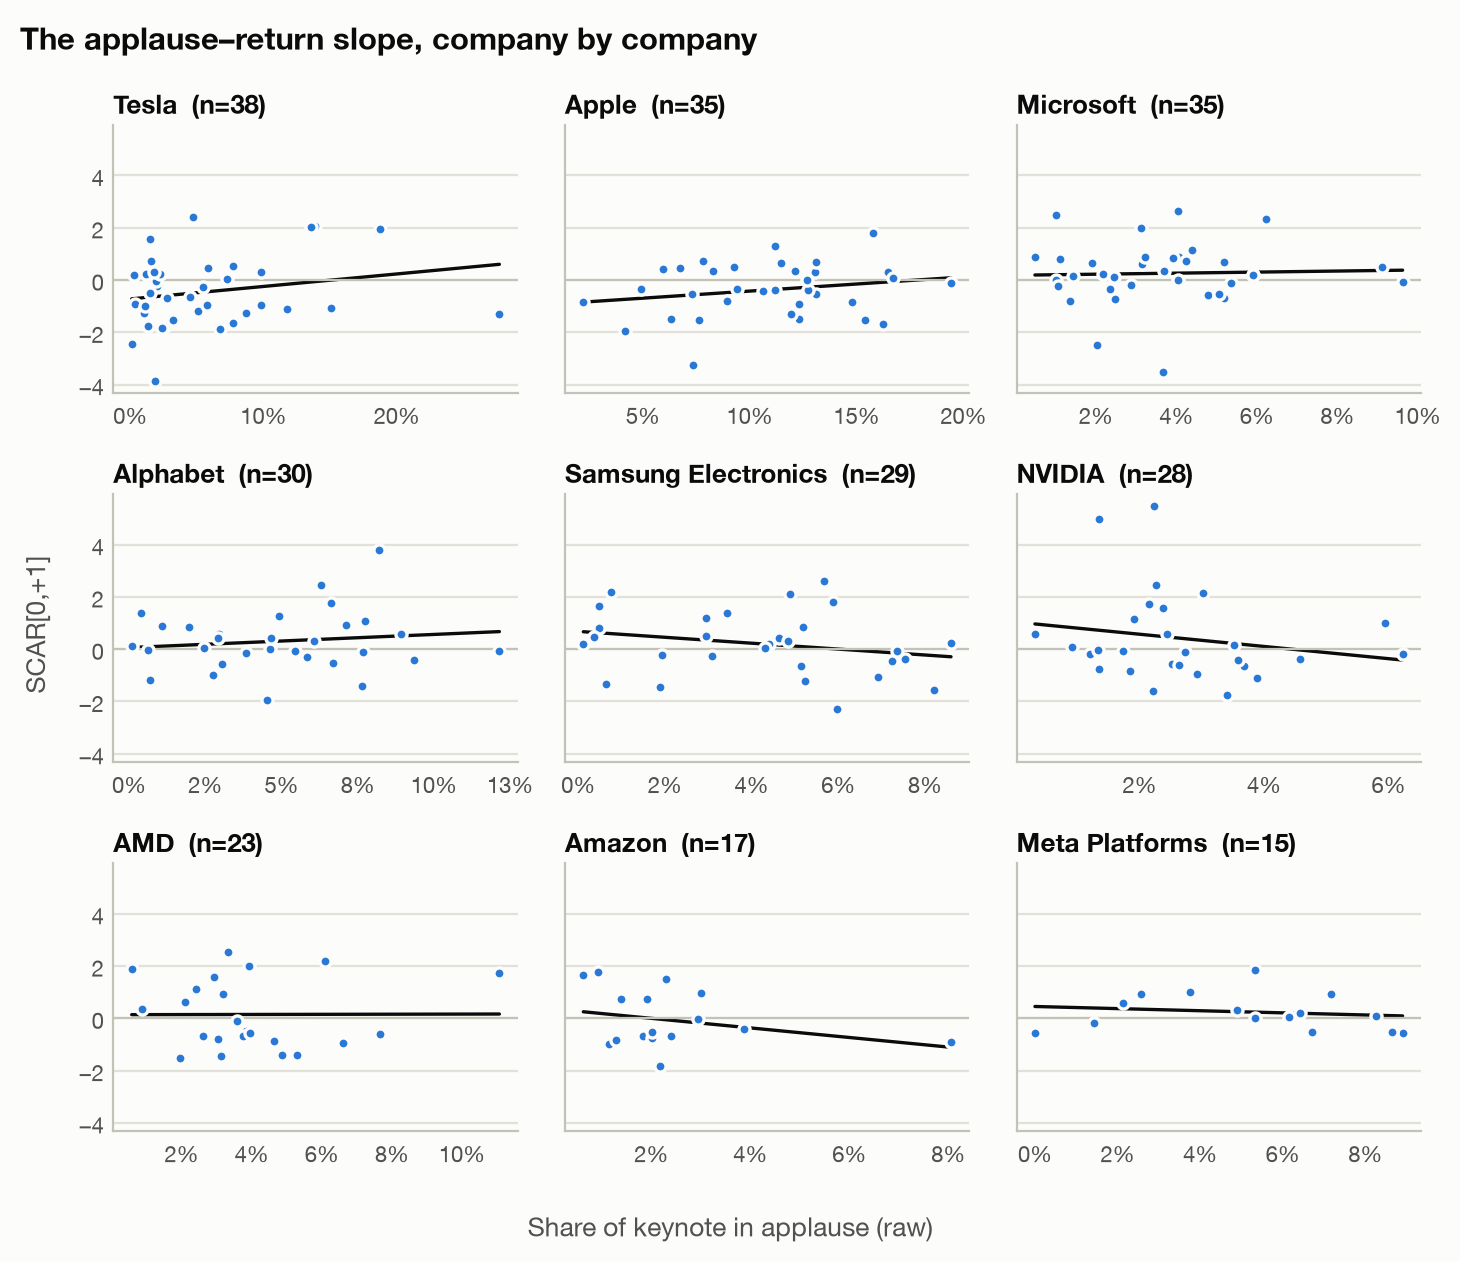

In [10]:
display(Image(filename=str(FIGURES / "company_multiples.png")))